# Dataset splits and score distributions

Prepare the AAV capsid surface region variants data and inspect the distributions of measured scores in the training, validation, and test splits.

In [1]:
# Prepare the data splits and inspect the distribution of measured scores for AAV capsid variants.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

#### Data split

Split the data into training, validation, and test sets at a ratio of 0.8 : 0.1 : 0.1.

## Load and inspect the data

In [2]:
# Load only the sequence, category, plasmid count, and viability score columns.
plm_data = "...\\pLM-bVAE\\reproduction_paper\\data\\"
aav_data = pd.read_csv(plm_data + "raw_data\\AAV_library_w_selection_scores.csv", sep=",", usecols=["aa_x", "category_x", "GAS1_plasmid_N", "GAS1_virus_S"]).reset_index(drop=True)

In [3]:
aav_data.shape

(243481, 4)

In [4]:
# Remove rows with negative infinite viability scores.
print("Rows with GAS1_virus_S equal to -inf:", (aav_data["GAS1_virus_S"] == -np.inf).sum())
aav_data = aav_data[aav_data["GAS1_virus_S"] != -np.inf].reset_index(drop=True)

# Select variants with plasmid counts greater than 100.
print("Rows with GAS1_plasmid_N greater than 100:", (aav_data["GAS1_plasmid_N"] > 100).sum())
aav_data_filtered = aav_data[aav_data["GAS1_plasmid_N"] > 100].reset_index(drop=True)

# Convert sequences to uppercase.
aav_data_filtered["aa_x"] = aav_data_filtered["aa_x"].str.upper()

Rows with GAS1_virus_S equal to -inf: 17840
Rows with GAS1_plasmid_N greater than 100: 173979


In [5]:
aav_data_filtered.shape

(173979, 4)

In [6]:
# For duplicate sequences, retain the row with the largest viability score.
print("Rows with duplicate aa_x sequences:", aav_data_filtered["aa_x"].duplicated().sum())
aav_data_filtered_deldp = aav_data_filtered.sort_values("GAS1_virus_S", ascending=False).drop_duplicates(subset="aa_x", keep="first").reset_index(drop=True)

Rows with duplicate aa_x sequences:

 9383


In [7]:
aav_data_filtered_deldp.shape

(164596, 4)

In [8]:
# Count rows in categories beginning with rnn.
print("Rows with category_x starting with rnn:", aav_data_filtered_deldp["category_x"].str.startswith("rnn").sum())

# Count rows in categories beginning with cnn.
print("Rows with category_x starting with cnn:", aav_data_filtered_deldp["category_x"].str.startswith("cnn").sum())

Rows with category_x starting with rnn: 48113
Rows with category_x starting with cnn: 47805


In [9]:
# Count rows in the selected RNN-designed category.
print("Rows with category_x equal to rnn_designed_plus_rand_train_walked:", (aav_data_filtered_deldp["category_x"] == "rnn_designed_plus_rand_train_walked").sum())

Rows with category_x equal to rnn_designed_plus_rand_train_walked: 16742


In [10]:
# Select the rnn_designed_plus_rand_train_walked category.
aav_data_filtered_deldp_categorized = aav_data_filtered_deldp[aav_data_filtered_deldp["category_x"] == "rnn_designed_plus_rand_train_walked"]
aav_data_filtered_deldp_categorized.shape

(16742, 4)

In [11]:
# Inspect the minimum and maximum sequence lengths.
print("Maximum aa_x sequence length:", aav_data_filtered_deldp_categorized["aa_x"].str.len().max())
print("Minimum aa_x sequence length:", aav_data_filtered_deldp_categorized["aa_x"].str.len().min())

Maximum aa_x sequence length: 43
Minimum aa_x sequence length: 28


In [12]:
# Prepend the wild-type sequence.
wt_seq = "DEEEIRTTNPVATEQYGSVSTNLQRGNR"
wt_row = aav_data_filtered_deldp[aav_data_filtered_deldp["aa_x"] == wt_seq]

aav_data_filtered_deldp_categorized_wt = pd.concat([wt_row, aav_data_filtered_deldp_categorized], ignore_index=True)
aav_data_filtered_deldp_categorized_wt.head(1)

,aa_x,category_x,GAS1_plasmid_N,GAS1_virus_S
0,DEEEIRTTNPVATEQYGSVSTNLQRGNR,wild_type,192,1.070797


In [13]:
# Drop the category and plasmid count columns.
aav_data_region = aav_data_filtered_deldp_categorized_wt.drop(columns=["category_x", "GAS1_plasmid_N"])

# Rename the sequence and viability score columns.
aav_data_region = aav_data_region.rename(columns={"aa_x": "seq", "GAS1_virus_S": "score"})

In [14]:
aav_data_region

,seq,score
0,DEEEIRTTNPVATEQYGSVSTNLQRGNR,1.070797
1,DETEIATTNPVATEQYGDVSTNLQGGGNER,3.734888
2,DEAEIRTTNPVATEQYGSVSNNLQKGGNDR,3.727338
3,DEAEIRTTNPVATEQYGVVSTNLQGGMQ,3.449196
4,NEEEISTTNPVATEQYGSVSTNLQHNGNP,3.250796
...,...,...
16738,DESEISENATTNPVAYECWGSVYYIENGGQQGQNPRH,-9.875272
16739,ATECWGIVATTIGINGGNHNGQPQTPLQEGEGHNDS,-9.979250
16740,DEATENTEIATNPVAYEQWGTVCPTDNGDQHQEDDHY,-10.035466
16741,ATECWGIVATTIGINGGNHNGQPVTPHQRGEGHNQS,-10.071762


In [15]:
# Count consecutive repeats in AAV sequences.
from collections import Counter
def count_consecutive_repeats(sequence):
    if not sequence:
        return 0
    count = 1
    max_count = 1
    for i in range(1, len(sequence)):
        if sequence[i] == sequence[i-1]:
            count += 1
            max_count = max(max_count, count)
        else:
            count = 1
    return max_count

print(aav_data_region['seq'].apply(count_consecutive_repeats).value_counts())

seq
2    13000
3     3297
4      252
1      158
5       32
6        3
8        1
Name: count, dtype: int64


In [16]:
# Count sequences by length in ascending order.
aav_data_region['seq'].apply(len).value_counts().sort_index()

seq
28      67
29     438
30    1444
31    2104
32    1905
33    1849
34    2017
35    1978
36    1623
37    1209
38    1037
39     622
40     262
41     128
42      44
43      16
Name: count, dtype: int64

#### Random data split

#### Training data for bVAE

In [17]:
# Shuffle the AAV data.
aav_data_region_shuffled = aav_data_region.sample(frac=1, random_state=42).reset_index(drop=True)

# Split the shuffled data into training, validation, and test sets at a ratio of 0.8:0.1:0.1.
train_size = int(0.8 * len(aav_data_region_shuffled))
dev_size = int(0.1 * len(aav_data_region_shuffled))
aav_train = aav_data_region_shuffled[:train_size]
aav_dev = aav_data_region_shuffled[train_size:train_size + dev_size]
aav_test = aav_data_region_shuffled[train_size + dev_size:]

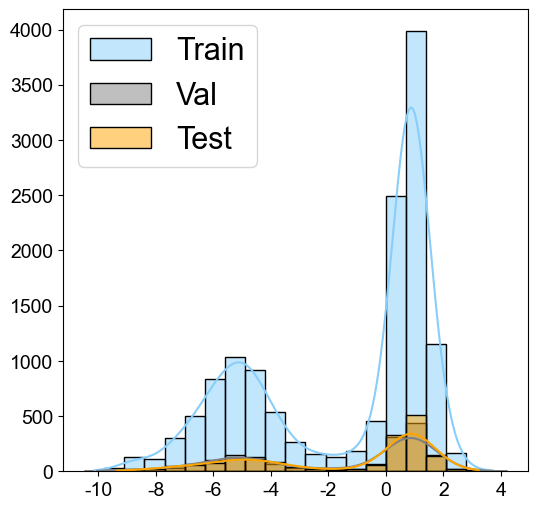

In [18]:
# Inspect the score distributions in the three splits.
plt.figure(figsize=(6, 6))

bin_width = 0.7

# Find the combined score range across the splits.
all_scores = pd.concat([aav_train["score"], aav_dev["score"], aav_test["score"]])

# Align bin boundaries to multiples of the bin width.
bin_min = np.floor(all_scores.min() / bin_width) * bin_width
bin_max = np.ceil(all_scores.max() / bin_width) * bin_width

# Use common bins for the three splits.
common_bins = np.arange(bin_min, bin_max + bin_width, bin_width)

sns.histplot(aav_train["score"], bins=common_bins, color="lightskyblue", kde=True, label="Train", alpha=0.5)
sns.histplot(aav_dev["score"], bins=common_bins, color="gray", kde=True, label="Val", alpha=0.5)
sns.histplot(aav_test["score"], bins=common_bins, color="orange", kde=True, label="Test", alpha=0.5)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel("")
plt.ylabel("")
plt.legend(fontsize=22)
plt.show()

In [19]:
# Extract the sequence column.
aav_train_seq = aav_train["seq"]
aav_dev_seq = aav_dev["seq"]
aav_test_seq = aav_test["seq"]

# Check for duplicates within each split.
print(aav_train_seq.shape[0], aav_dev_seq.shape[0], aav_test_seq.shape[0])

# Check for overlapping sequences between splits.
print(set(aav_train_seq) & set(aav_dev_seq), set(aav_train_seq) & set(aav_test_seq), set(aav_dev_seq) & set(aav_test_seq))

# Check the split sizes and proportions.
aav_train_seq.shape[0] / aav_data_region_shuffled.shape[0], aav_dev_seq.shape[0] / aav_data_region_shuffled.shape[0], aav_test_seq.shape[0] / aav_data_region_shuffled.shape[0]

13394 1674 1675
set() set() set()


(0.7999761094188617, 0.09998208206414622, 0.10004180851699218)